# Numerical Optimization of gut-immune interactions

In [208]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.optimize import fsolve
from math import erf
import numba as nb
import multiprocessing as mp
from tqdm import tqdm
from joblib import Parallel, delayed
import os
import time

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

### A. Define model parameters and useful functions

In [286]:
# Define model parameters

##  microbes ##
nG = 10
A = 0.0*np.random.binomial(n = 1, p = 0.2, size = (nG,nG)) # species competition matrix
A[np.arange(0,nG),np.arange(0,nG)] = 0.0
dG = 0.1*np.ones(nG) # microbial death rate
q = np.random.dirichlet(np.ones(nG)) #0.01*np.random.binomial(n = 2, p = 0.7, size = nG) # immigration rate of microbes into the gut
mu = np.random.binomial(n = 1, p = 0.2, size = nG) # rates of breaching gut epithelium

## antibodies ##
na = int(0.5*nG)
F = np.random.binomial(n = 1, p = 0.2, size=(nG,na)) # antibody cross-reactivity: F_i,a = f_a,i
P0 = np.random.dirichlet(np.ones(na))

## resources ##
nR = int(0.5*nG)
k = np.ones(nR) # resource input rate
w = 0.5*np.ones(nR) # resource clearance rate
C = np.random.dirichlet(np.ones(nR), size = nG) # resource utilization matrix

## benefits ##
nB = np.maximum(2,int(0.1*nG))
D0 = np.random.binomial(n = 1, p = 0.2, size=(nG,nB)) # microbe benefit matrix
beta = np.ones(nB) # scaling of microbe benefit relative to harm
u = np.ones(nB) # decay rate of benefits

## Treg receptors ##
ngam = int(0.5*nG)
M = np.random.binomial(n = 1, p = 0.5, size=(nG,ngam)) # Treg cross-reactivity: M_i,a = m_r,a
gam0 = np.random.dirichlet(np.ones(ngam))
gam_min, gam_max = 0,1
lam = 0.01 # strength of inflammatory pressure

In [287]:
# Define functions

def H(P, gam):
    return np.ones(nG)

def Lam(P, gam):
    return lam*np.outer(np.ones(nG) - M.dot(gam), (np.ones(nG) - F.dot(P)).dot(np.diag(mu)))

def G_ss(P, gam):
    
    L = lam*np.diag((np.ones(nG) - M.dot(gam))*(np.ones(nG) - F.dot(P))*mu)
    guess = np.maximum(np.linalg.solve(Lam(P, gam)-A, C.dot(k/w)),0)
    
    def func(G):
        return np.diag(-Lam(P, gam).dot(G) + C.dot(k/(w + C.T.dot(G))) + A.dot(G) - dG).dot(G) + 0.0*np.random.binomial(n = 1, p = q, size = nG)
    
    root = fsolve(func, guess)
    
    return np.maximum(root,0)

def B(P,gam, G):
    out =  np.diag(1/u).dot(D0.T).dot(np.diag(np.ones(nG) - F.dot(P)).dot(G.T))
    return out

# def objective(pg):
#     P, gam = pg[:-1], pg[-1]
    
#     cost = (1-h(gam)*F.dot(P)).T.dot(g_ss(P,gam)*mu) - beta*B(P,gam)
#     grad_P = (-gam*np.diag(mu).dot(F)).T.dot(np.linalg.solve(A, Lam*gam*F.dot(P)-C.dot(r))) \
#             + (Lam*gam*F).T.dot(np.linalg.solve(A.T, mu - gam*np.diag(mu).dot(F.dot(P)) - beta*r.T.dot(D0)))
#     grad_gam = (-np.diag(mu).dot(F.dot(P))).T.dot(np.linalg.solve(A, Lam*gam*F.dot(P)-C.dot(r))) \
#             + (Lam*F.dot(P)).T.dot(np.linalg.solve(A.T, mu - gam*np.diag(mu).dot(F.dot(P)) - beta*r.T.dot(D0)))
    
#     return cost, np.append(grad_P,grad_gam)

In [288]:
# print(Lam(P0,gam0))
# print(G_ss(P0,gam0))

### r. Simulate microbe-immune dynamics

In [289]:
# Simulate microbe dynamics
from scipy.integrate import odeint

# time points
sim_dur = 300
q_t = np.random.binomial(n = 1, p = 0.2, size = nG)
t_infect = 0.5

# function that returns dx/dt = A x 
def model(x0,t):
    R = x0[0:nR]
    G = x0[nR:nR+nG]
    B = x0[-nB:]
    dgdt = (C.dot(k/(w + C.T.dot(G))) + (A-Lam(P0,gam0)).dot(G) - dG).dot(np.diag(G*(G > 0))) + 0*(0*(1-q_t)*q +(t_infect*sim_dur + 1 >= t >= t_infect*sim_dur)*q_t)
    return list(dgdt.ravel())

# initial condition
G0 = np.ones(nG) #0.1*np.random.binomial(n = 1, p = 0.7, size = nG)
t = np.linspace(0,sim_dur, num = 1000)

# solve ODE
G = odeint(model,list(G0),t)
imm_load = (Lam(P0,gam0).dot(G.T)).T

[Text(0.5, 0, 'time, $t$ (days)'), Text(0, 0.5, 'microbiome benefits, $B(t)$')]

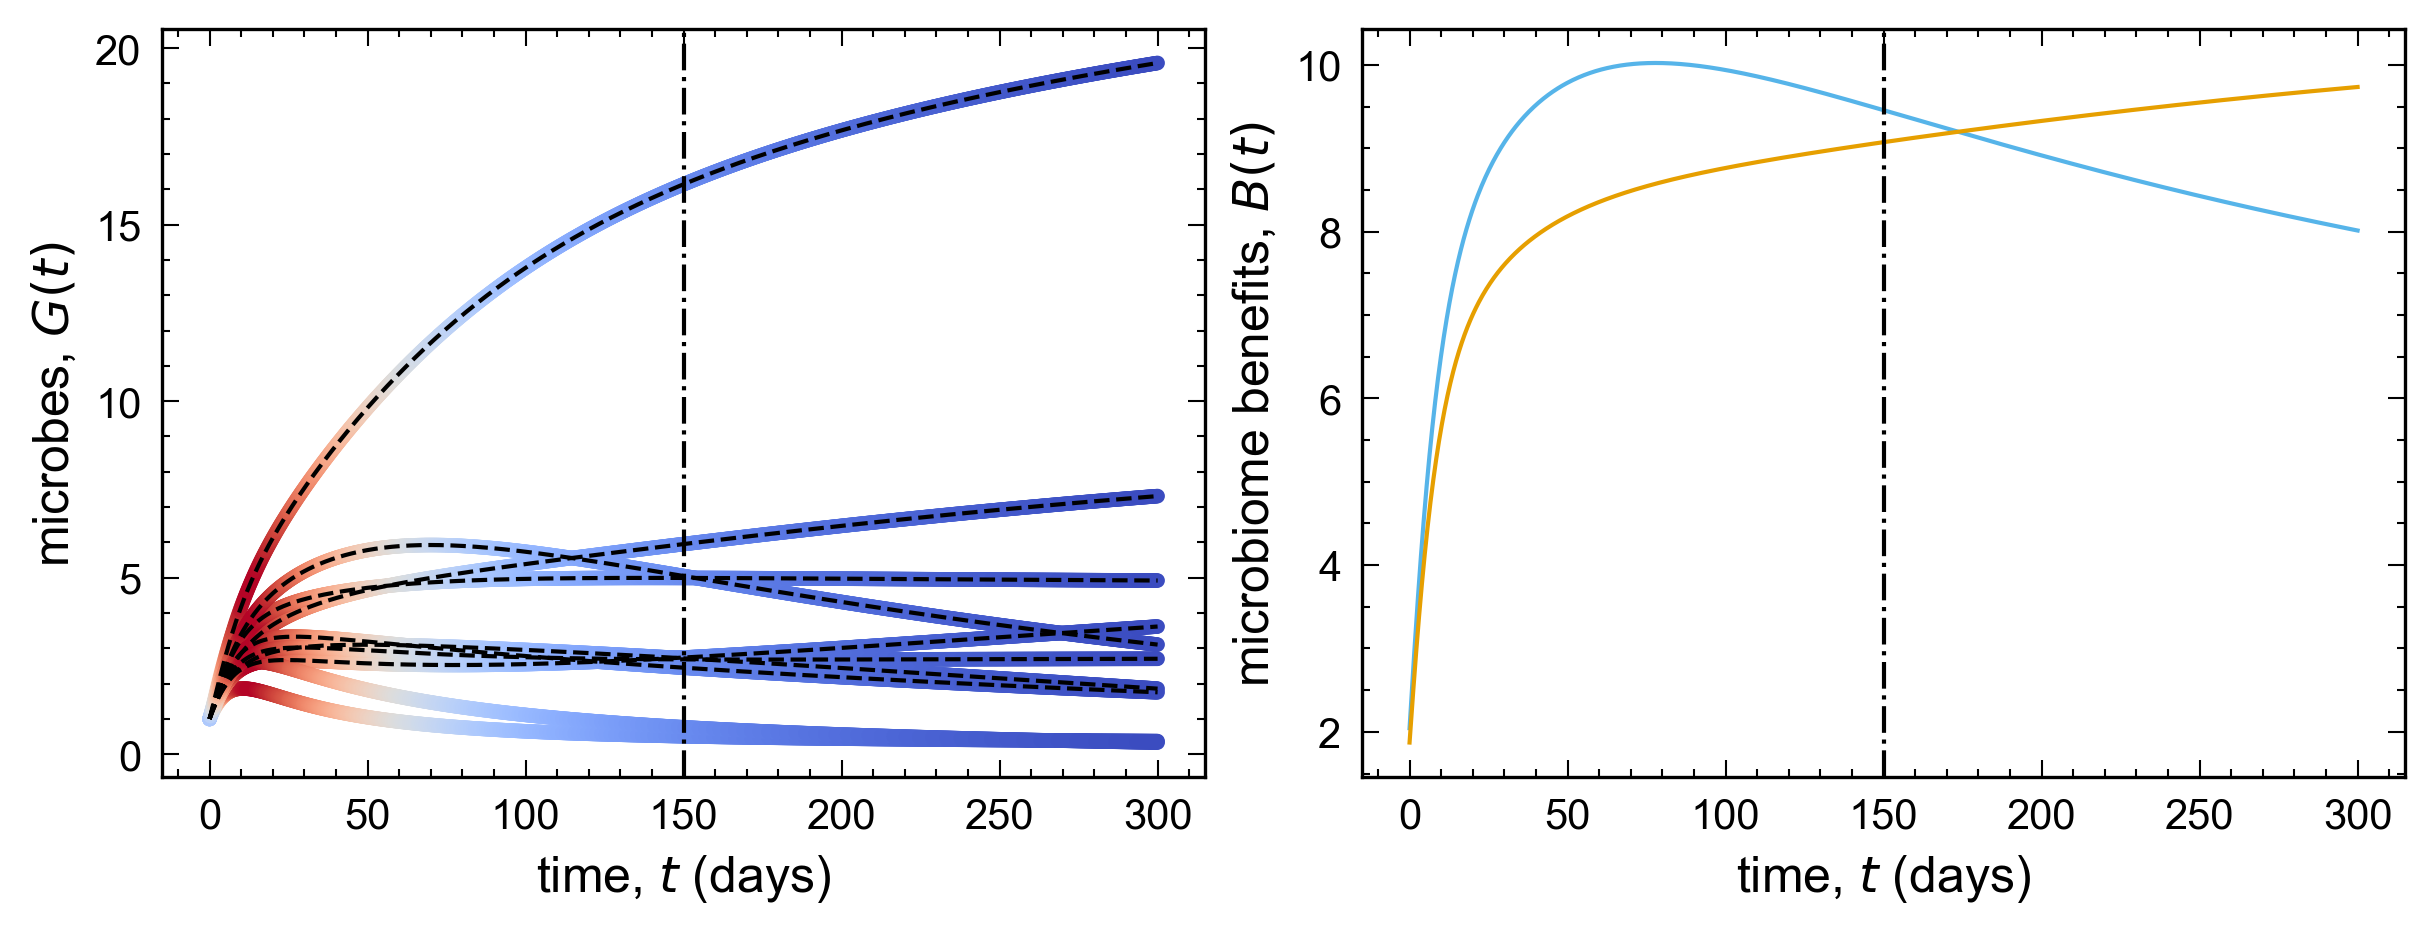

In [290]:
# Plot simulated dynamics
fig, (ax1, ax2) = plt.subplots(1,2, dpi = 150, constrained_layout=True, sharex = False, figsize=(8,3))

for j in np.arange(nG):
    ax1.scatter(t, G[:,j], marker ='.', c = imm_load[:,j], cmap='coolwarm') #, norm=mpl.colors.LogNorm())
    if mu[j] == 0:
        ax1.plot(t, G[:,j], color = 'k', linestyle = '--')
        
ax1.axvline(x = t_infect*sim_dur, color = 'k', linestyle = '-.')
ax1.set(xlabel=r'time, $t$ (days)', ylabel=r'microbes, $G(t)$')

ax2.plot(t, B(P0,gam0, G).T)
ax2.axvline(x = t_infect*sim_dur, color = 'k', linestyle = '-.')
ax2.set(xlabel=r'time, $t$ (days)', ylabel=r'microbiome benefits, $B(t)$')

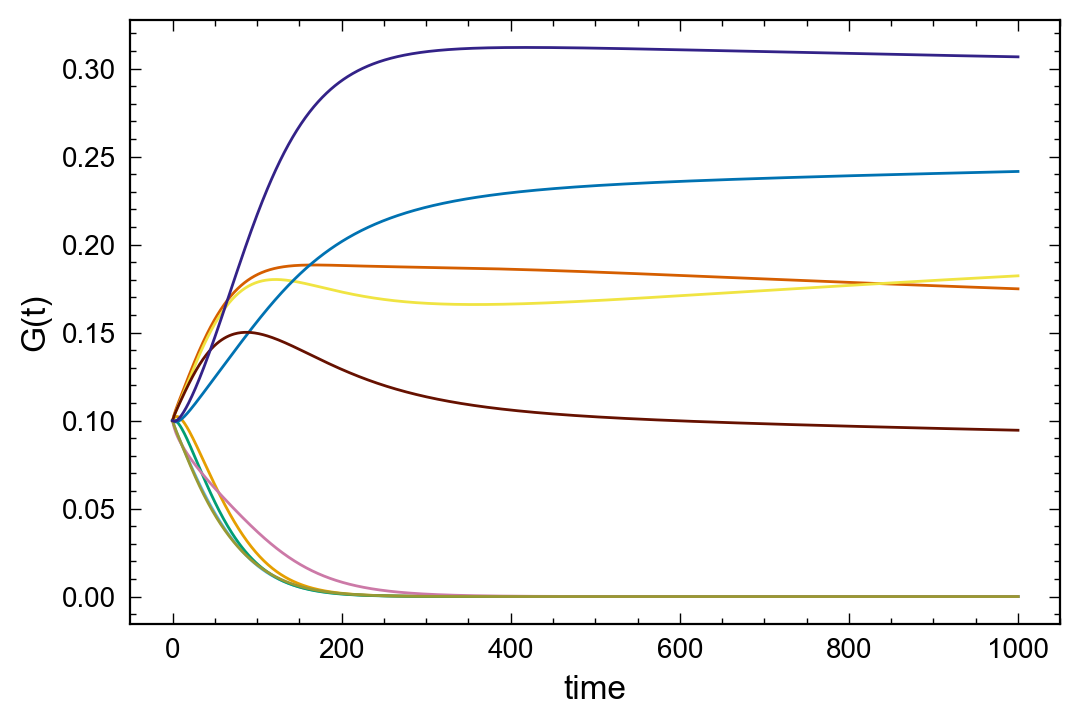

In [221]:
G_sc = np.array([i/np.sum(i, axis = 0) for i in G])

plt.plot(t, G_sc)

plt.xlabel('time')
plt.ylabel('G(t)')
plt.show()

In [9]:
# Sanity checks
objective(np.append(P0,gam0))
#B(P0,gam0)
np.abs(g[-1] - g_ss(P0,gam0))/g[-1]

NameError: name 'objective' is not defined

### C. Find optimal repertoire and tolerance level

In [ ]:
# Run optimization for a test system
reltol = 1e-8
popt = minimize(objective, pg0=np.append(P0,gam0), reltol=reltol,
                             maxiters=2e4, show_progress=True,
                             nboundupdate=1e4)

print(popt)

In [ ]:
#print(F.dot(np.ones(na)/na))
print(np.corrcoef(F.dot(popt[:-1]),mu))

In [ ]:
# Next think about a better stopping condition than just reaching the lower bound. 
# Also figure out a way to make sense of the results. Which antibodies get preferred and how does it translate into protection.

In [ ]:
g_ss(P0,gam0)*mu

In [ ]:
# Implement proximal gradient optimization for repertoire: https://pypi.org/project/pyproximal/
def project(pg, mask=None):
    """ Take a vector pg (with possible nonnegative entries and non-normalized)
        and project it onto the unit simplex. Take value gamma and project it onto an interval
        mask:   do not project these entries
                project remaining entries onto lower dimensional simplex
    """
    x, z = pg[:-1], pg[-1]
    
    if mask is not None:
        mask = np.asarray(mask)
        xsorted = np.sort(x[~mask])[::-1]
        # remaining entries need to sum up to 1 - sum x[mask]
        sum_ = 1.0 - np.sum(x[mask])
    else:
        xsorted = np.sort(x)[::-1]
        # entries need to sum up to 1 (unit simplex)
        sum_ = 1.0
    lambda_a = (np.cumsum(xsorted) - sum_) / np.arange(1.0, len(xsorted)+1.0)
    for i in np.arange(len(lambda_a)-1):
        if lambda_a[i] >= xsorted[i+1]:
            astar = i
            break
    else:
        astar = -1
    p = np.maximum(x-lambda_a[astar],  0)
    if mask is not None:
        p[mask] = x[mask]
    # project gam
    g = np.maximum(gam_min, np.minimum(z, gam_max))
    
    return np.append(p, g)

def minimize(objective, pg0,
             nboundupdate=100,
             reltol=1e-4, abstol=0.0, maxiters=1e7,
             algo='fast',
             show_progress=False,
             callback=None,
             full_return=False,
             mask=None):
    """
    minimize     objective(P_r)
    subject to   0.0 <= P_r
                 sum(P_r) = 1
    parameters
    ----------
    objective : function returning cost, gradient
    pg0 : starting guess for receptor Pr and tolerance gam
    nboundupdate : number of iteration between lower bound updates
    reltol, abstol, maxiters: numerical parameter
    algo: fast or normal algorithm
    show_progress: print status information during the run
    full_return: also return dict with information about optimization
    mask: Boolean array with directions along which not to optimize
    output
    ------
    optimal solution
    """

    if mask is not None:
        mask = np.asarray(mask)

        def mobjective(x):
            f, grad = objective(x)
            if grad is not None:
                grad[mask] = 0.0
            return f, grad
        mobjective = mobjective
        mproject = lambda pg: project(pg, mask)
    else:
        mobjective = objective
        mproject = project
    # initialize p and g from function input
    pg = mproject(np.asarray(pg0))
    # counting variable for number of iterations
    k = 0
    # lower bound for the cost function
    low = -beta*B(pg[:-1],pg[-1]) #0.0

    # setup for accelerated algorithm
    if algo == 'fast':
        y = pg
        f, grad = mobjective(pg)
        # starting guess for gradient scaling parameter 1 / | nabla f |
        s = 1.0 / np.linalg.norm(grad)
        # refine by backtracking search
        while True:
            y_new = mproject((y - s * grad))
            # abs important as values close to machine precision
            # might become negative in fft convolution screwing
            # up cost calculations
            f_new, grad_new = mobjective(y_new)
            if f_new < f + np.dot(y_new - y, grad.T) + \
                    0.5 * np.linalg.norm(y_new - y)**2 / s:
                break
            s *= 0.8
        # reduce s by some factor as optimal s might become smaller during
        # the course of optimization
        s /= 3.0

    told = time.time()
    while k < maxiters:
        k += 1
        f, grad = mobjective(pg)

        # update lower bound on cost function
        # initialize at beginning (k=1) and then every nboundupdateth iteration
        if (k % nboundupdate == 0) or (k == 1):
            if mask is not None:
                i = np.argmin(grad[~mask])
                low = max((low, f - np.sum(pg * grad) + grad[~mask][i]))
            else:
                i = np.argmin(grad)
                low = max((low, f - np.sum(pg * grad) + grad[i]))
            gap = f - low
            if callback:
                callback(f, pg)
            if show_progress:
                print('%g: f %e, gap %e, relgap %e' % (k, f, gap, np.abs(gap/low) if low != 0 else np.inf))
            if ((low != 0 and np.abs(gap/low) < reltol) or np.abs(gap) < abstol):
                if show_progress:
                    print( 'stopping criterion reached')
                break

        if algo == 'fast':
            f, grad = mobjective(y)
            pg, pgold = mproject(y - s * grad), pg
            y = pg + k/(k+3.0) * (pg - pgold)
        else:
            # generate feasible direction by projection
            s = 0.1
            d = mproject(pg - s * grad) - pg
            # Backtracking line search
            deriv = np.dot(grad.T, d)
            alpha = 0.1
            # in (0, 0.5)
            p1 = 0.2
            # in (0, 1)
            p2 = 0.25
            fnew, grad = mobjective(pg + alpha * d)
            while fnew > f + p1*alpha*deriv:
                alpha *= p2
                fnew, grad = mobjective(pg + alpha * d)
            pg += alpha * d

    else:
        print('warning: maxiters reached before convergence')
    if show_progress:
        print('niters %e, t per iteration %e' % (k, (time.time() - told) / k))
        print('cost %e, low %e, gap %e, relgap %e' % (f, low, gap, gap/low if low != 0 else np.inf))

    if not full_return:
        return pg
    return pg, dict(niter=k, f=f, low=low)